# Sliding window graph

Sliding window graph is a special type of graph, that is made of multiple subgraphs, connected in sequential order.

## Creation process

We take our segment of a timeseries, and disect it into smaller segments with sliding window technique. Then we transform these segments of timeseries into graphs, using provided strategy, treat these graphs as nodes and sequentially connect them to form new snake like graph. This graph has for nodes subgraphs, each with the same number of nodes. Then we can combine identical subgraphs (subgraphs that have same edges) and we have our completed sliding window graph. 

### Example:

In [2]:
import os, sys
sys.path.append("/var/scratch/sdu/ts2g2")

import warnings
warnings.filterwarnings('ignore')

import utils 
from visualization import draw_g
from strategies.ts2g.strategy_builder import get_ts2g_strategy_builder
from strategies.view import get_view_strategy
from strategies.merge import get_link_multigraph_strategy_builder
from pipeline import T2G2Pipeline

amazon_path = os.path.join(os.getcwd(), "amazon", "AMZN.csv")

Applying viewing strategy: <strategies.view.views.SliceView object at 0x7fd4b7106570>
Number of dimensions: 1; total windows: 1
Applying viewing strategy: <strategies.view.views.FixedOverlapWindow object at 0x7fd4b6f2aba0>
Number of dimensions: 1; total windows: 196


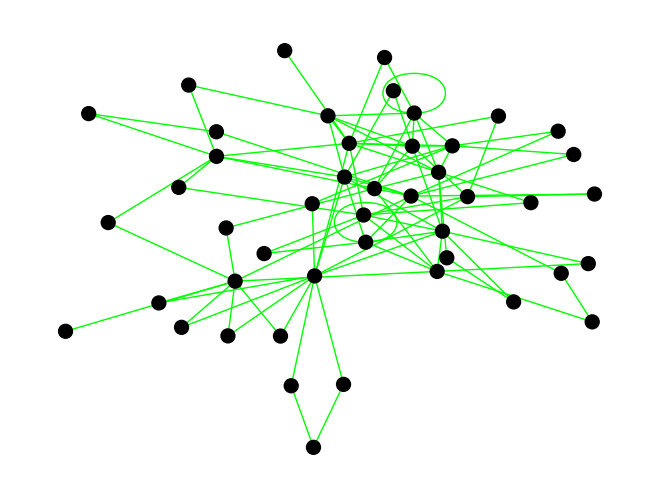

In [3]:


ts_data = utils.CsvFile(amazon_path, "Close").from_csv()

view_seg = get_view_strategy("slice")(start_index=100, end_index=300)
view_win = get_view_strategy("sliding_window")(window_size=5, step_size=1)

ts2g_builder = get_ts2g_strategy_builder(method="natural_visibility")
ts2g_strategy = ts2g_builder().get_strategy()

merge_builder = get_link_multigraph_strategy_builder()
link_strategy = merge_builder().sliding_window()

pipeline = T2G2Pipeline()
(
    pipeline.load_timeseries(ts_data)
            .viewing(view_seg)
            .viewing(view_win)
            .to_graph(ts2g_strategy)
            .link_graphs(link_strategy)
            .combine_identical_subgraphs()
)

G = pipeline.get_Graph()
draw_g(G)